# Complete Q-MHAF Training for Four-Class Sleep Apnea Classification

This notebook runs the entire pipeline with a single **Run All**: data and label checks,
leakage tests, self-supervised pretraining, nested five-fold training, validation-only
calibration, architecture and signal ablations, OOF aggregation, plots, and result packaging.

The research target is accuracy above 90%, but the notebook neither fabricates nor
guarantees results. Final evaluation uses only subject-level outer-test predictions.
A modern GPU with 16–24 GB of memory is recommended for a complete run.

In [1]:
from pathlib import Path
import os, sys, json, time, shutil, subprocess, platform, random, zipfile

def locate_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / 'deep_learning').is_dir() and (candidate / 'processed_shhs_v1').is_dir():
            return candidate
    raise FileNotFoundError('Project root containing deep_learning/ and processed_shhs_v1/ was not found')

PROJECT_ROOT = locate_project_root(Path.cwd().resolve())
os.chdir(PROJECT_ROOT)

RUN_MODE = os.environ.get('QMHAF_RUN_MODE', 'production').lower()
RUN_SSL = True
RUN_MAIN_TRAINING = True
RUN_ABLATIONS = True
FORCE_RETRAIN = False
MAIN_FOLDS = [0, 1, 2, 3, 4]
ABLATION_FOLDS = [0]

PROFILES = {
    'production': dict(ssl_epochs=30, supervised_epochs=35, ablation_epochs=10, ssl_crop_epochs=160),
    'smoke': dict(ssl_epochs=1, supervised_epochs=1, ablation_epochs=1, ssl_crop_epochs=40),
}
if RUN_MODE not in PROFILES:
    raise ValueError(f'Unknown RUN_MODE={RUN_MODE!r}')
PROFILE = PROFILES[RUN_MODE]

RUN_ROOT = PROJECT_ROOT / 'server_run'
LOG_DIR = RUN_ROOT / 'logs'
FIGURE_DIR = RUN_ROOT / 'figures'
LOG_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print('PROJECT_ROOT:', PROJECT_ROOT)
print('RUN_MODE:', RUN_MODE, PROFILE)

PROJECT_ROOT: /workspace/mohandes/qmhaf_shhs_training_bundle
RUN_MODE: production {'ssl_epochs': 30, 'supervised_epochs': 35, 'ablation_epochs': 10, 'ssl_crop_epochs': 160}


## 1. Environment Checks and Setup

In [2]:
# required = ['numpy', 'pandas', 'pyarrow', 'scipy', 'sklearn', 'h5py', 'torch',
#             'matplotlib', 'seaborn', 'openpyxl']
# missing = []
# for module in required:
#     try:
#         __import__(module)
#     except Exception:
#         missing.append(module)
# if missing:
#     print('Installing missing dependencies:', missing)
    # subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', 'deep_learning/requirements.txt'])
    # subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'matplotlib', 'seaborn', 'nbformat'])

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 20260919
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
vram_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3 if torch.cuda.is_available() else 0
cpu_count = os.cpu_count() or 2
# workers = min(8, max(2, cpu_count // 2))
workers = 0
if vram_gb >= 20:
    main_batch, accumulation, ssl_batch = 16, 1, 32
elif vram_gb >= 10:
    main_batch, accumulation, ssl_batch = 8, 1, 16
elif vram_gb >= 6:
    main_batch, accumulation, ssl_batch = 6, 2, 12
else:
    main_batch, accumulation, ssl_batch = 4, 2, 6

if RUN_MODE == 'smoke':
    main_batch = min(main_batch, 2); ssl_batch = min(ssl_batch, 2); workers = 0
print(dict(python=sys.version.split()[0], torch=torch.__version__, device=device_name,
           vram_gb=round(vram_gb, 2), main_batch=main_batch, accumulation=accumulation,
           ssl_batch=ssl_batch, workers=workers))

{'python': '3.13.11', 'torch': '2.8.0+cu129', 'device': 'NVIDIA GeForce RTX 3090', 'vram_gb': 24.0, 'main_batch': 16, 'accumulation': 1, 'ssl_batch': 32, 'workers': 0}


In [3]:
def run_command(command, log_name, skip_path=None):
    if skip_path and Path(skip_path).exists() and not FORCE_RETRAIN:
        print('SKIP existing:', skip_path)
        return
    command = [str(x) for x in command]
    print('\nRUN:', ' '.join(command))
    log_path = LOG_DIR / log_name
    with log_path.open('w', encoding='utf-8') as log:
        process = subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, bufsize=1, cwd=PROJECT_ROOT)
        for line in process.stdout:
            print(line, end='')
            log.write(line); log.flush()
        return_code = process.wait()
    if return_code:
        raise RuntimeError(f'Command failed ({return_code}); inspect {log_path}')

run_command([sys.executable, '-m', 'unittest', '-v',
             'training.test_training_assets', 'deep_learning.test_deep_pipeline'],
            '00_integrity_tests.log')


RUN: /bin/python -m unittest -v training.test_training_assets deep_learning.test_deep_pipeline
test_allnight_is_finite (training.test_training_assets.TrainingAssetTests.test_allnight_is_finite) ... ok
test_checksums (training.test_training_assets.TrainingAssetTests.test_checksums) ... ok
test_folds_are_disjoint_and_complete (training.test_training_assets.TrainingAssetTests.test_folds_are_disjoint_and_complete) ... ok
test_no_forbidden_columns (training.test_training_assets.TrainingAssetTests.test_no_forbidden_columns) ... ok
test_shape_and_identity (training.test_training_assets.TrainingAssetTests.test_shape_and_identity) ... ok
test_target_thresholds (training.test_training_assets.TrainingAssetTests.test_target_thresholds) ... ok
test_annotations_are_targets_not_inputs (deep_learning.test_deep_pipeline.DeepPipelineTests.test_annotations_are_targets_not_inputs) ... ok
test_artifact_hashes (deep_learning.test_deep_pipeline.DeepPipelineTests.test_artifact_hashes) ... ok
test_auxiliary_s

## 2. Cohort, Label, and Baseline Audit

,subject_id,target_ahi,target_class,target_class_name,target_version,qc_pass,fold
0,shhs1-200001,3.994674,0,normal,ahi_a0h3_local_v1,True,2
1,shhs1-200002,23.076923,2,moderate,ahi_a0h3_local_v1,True,1
2,shhs1-200003,8.368201,1,mild,ahi_a0h3_local_v1,True,0
3,shhs1-200004,2.192691,0,normal,ahi_a0h3_local_v1,True,2
4,shhs1-200005,5.189189,1,mild,ahi_a0h3_local_v1,True,2


target_class_name,mild,moderate,normal,severe
fold,,,,
0,414,187,464,92
1,414,187,464,92
2,414,188,463,92
3,414,188,463,92
4,415,187,463,92


Target SHA256: 2d1b93a8eb3be485d7373ae45fc05c75125ed38a890c0c89dfbea1666cd7dd84
Subjects: 5785 | QC pass: 5197


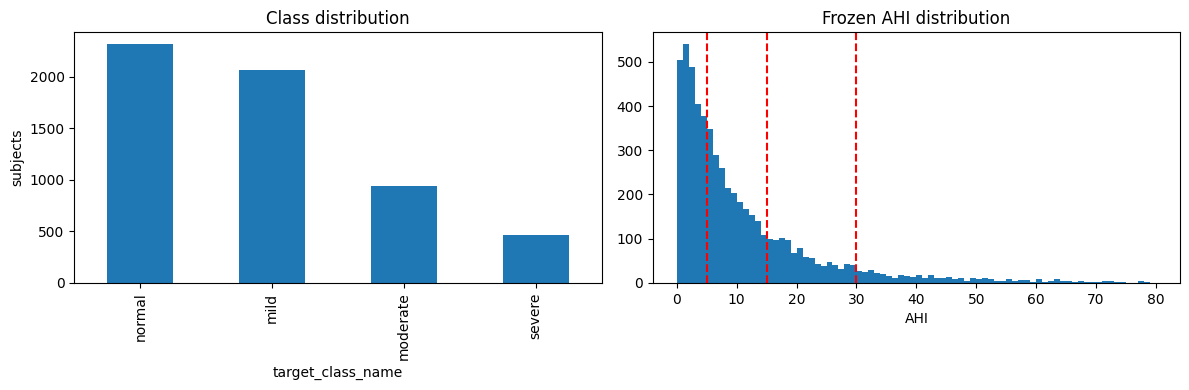

In [4]:
target = pd.read_parquet('training/targets/ahi_a0h3_local_v1/targets.parquet')
deep_manifest = pd.read_parquet('deep_learning/data/ahi_a0h3_local_v1/deep_manifest.parquet')
definition = json.loads(Path('training/targets/ahi_a0h3_local_v1/target_definition.json').read_text())
display(target.head())
display(pd.crosstab(target['fold'], target['target_class_name']))
print('Target SHA256:', definition['target_sha256'])
print('Subjects:', len(target), '| QC pass:', int(target.qc_pass.sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target.target_class_name.value_counts().reindex(['normal','mild','moderate','severe']).plot.bar(ax=axes[0])
axes[0].set_title('Class distribution'); axes[0].set_ylabel('subjects')
axes[1].hist(target.target_ahi, bins=80, range=(0, 80))
for threshold in [5, 15, 30]: axes[1].axvline(threshold, color='red', ls='--')
axes[1].set_title('Frozen AHI distribution'); axes[1].set_xlabel('AHI')
plt.tight_layout(); plt.savefig(FIGURE_DIR/'cohort_labels.png', dpi=180); plt.show()

,model,accuracy,macro_f1,balanced_accuracy,qc_pass_accuracy
0,lgbm_logahi_regression,0.766292,0.754007,0.739428,0.770252
1,lgbm_unweighted,0.762316,0.742674,0.728611,0.764480
2,lgbm_balanced,0.759205,0.744954,0.736845,0.762170
3,extra_trees_balanced,0.754365,0.738208,0.729496,0.758322
4,logistic_balanced,0.729818,0.713901,0.726690,0.738311
5,dummy_prior,0.400519,0.142989,0.250000,0.404079


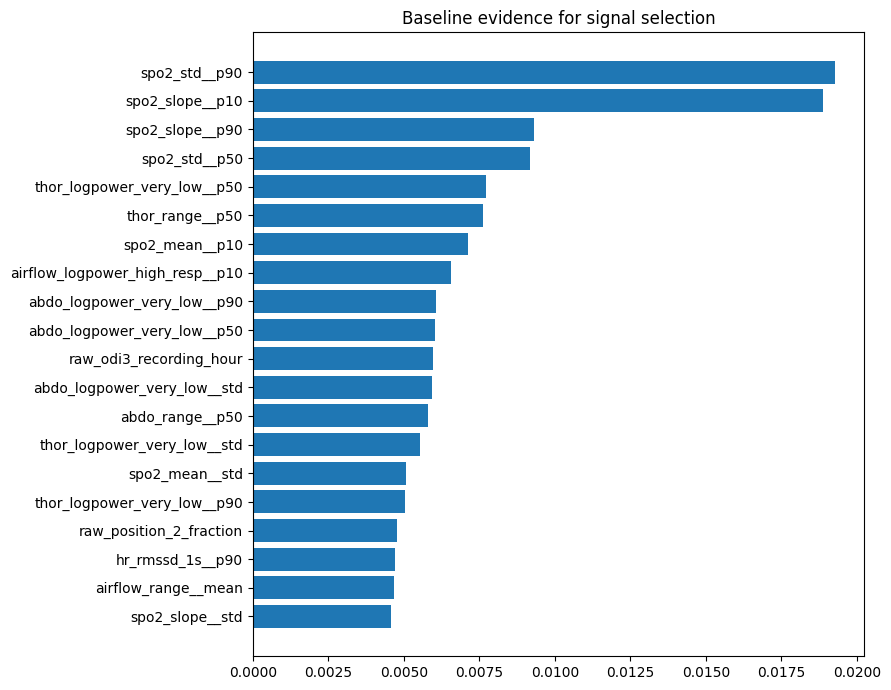

In [5]:
baseline_path = Path('training/results/ahi_a0h3_local_v1/completed_baseline_summary.csv')
baseline = pd.read_csv(baseline_path)
display(baseline[['model','accuracy','macro_f1','balanced_accuracy','qc_pass_accuracy']].sort_values('accuracy', ascending=False))

importance_path = Path('training/results/ahi_a0h3_local_v1/allnight_all/lgbm_logahi_regression/feature_importance.csv')
importance = pd.read_csv(importance_path).head(20).sort_values('importance')
plt.figure(figsize=(9, 7)); plt.barh(importance.feature, importance.importance)
plt.title('Baseline evidence for signal selection'); plt.tight_layout()
plt.savefig(FIGURE_DIR/'baseline_feature_importance.png', dpi=180); plt.show()

## 3. Raw Inputs and Architecture

The main inputs are airflow/THOR/ABDO at 10 Hz and SpO₂/HR at 1 Hz. Sleep stages
and respiratory events are auxiliary targets used only during training and are
unavailable at inference. The model learns the AHI numerator and denominator
separately, then aligns the four-class ordinal output with the continuous AHI.

In [6]:
from deep_learning.data import SHHSRawNightDataset, collate_nights
from deep_learning.model import QMHAFNet, ModelConfig, multitask_loss

sample_dataset = SHHSRawNightDataset(
    deep_manifest.iloc[:2], Path('deep_learning/data/ahi_a0h3_local_v1/deep_targets.h5'),
    training=False, ssl_crop_epochs=40)
sample_batch = collate_nights([sample_dataset[0], sample_dataset[1]])
model = QMHAFNet(ModelConfig())
with torch.no_grad(): sample_output = model(sample_batch)
print('parameters:', sum(p.numel() for p in model.parameters()))
print('resp:', tuple(sample_batch['resp'].shape), 'low-rate:', tuple(sample_batch['low'].shape))
print('probability sums:', sample_output['class_probabilities'].sum(1).tolist())
del model, sample_batch, sample_output

parameters: 1550605
resp: (2, 40, 3, 300) low-rate: (2, 40, 5, 30)
probability sums: [1.0, 1.0]


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


## 4. Independent Self-Supervised Pretraining for Each Outer Fold

In [7]:
SSL_DIR = Path('deep_learning/pretrained_smoke/ahi_a0h3_local_v1') if RUN_MODE == 'smoke' else Path('deep_learning/pretrained/ahi_a0h3_local_v1')
SSL_DIR.mkdir(parents=True, exist_ok=True)
if RUN_SSL:
    for fold in MAIN_FOLDS:
        checkpoint = SSL_DIR / f'ssl_outer_fold_{fold}.pt'
        command = [sys.executable, '-u', 'deep_learning/pretrain_ssl.py',
                   '--test-fold', fold, '--epochs', PROFILE['ssl_epochs'],
                   '--batch-size', ssl_batch, '--crop-epochs', PROFILE['ssl_crop_epochs'],
                   '--workers', workers, '--output-dir', SSL_DIR]
        if RUN_MODE == 'smoke': command += ['--max-steps-per-epoch', 2]
        run_command(command, f'10_ssl_fold_{fold}.log', checkpoint)


RUN: /bin/python -u deep_learning/pretrain_ssl.py --test-fold 0 --epochs 30 --batch-size 32 --crop-epochs 160 --workers 0 --output-dir deep_learning/pretrained/ahi_a0h3_local_v1
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
{"epoch": 1, "ssl_loss": 1.4259686961616438, "lr": 0.0002992056748283994}
{"epoch": 2, "ssl_loss": 1.2661287968920678, "lr": 0.0002968314021064014}
{"epoch": 3, "ssl_loss": 1.2565561963110854, "lr": 0.00029290319486279675}
{"epoch": 4, "ssl_loss": 1.2544318486734765, "lr": 0.00028746409135817674}
{"epoch": 5, "ssl_loss": 1.2542935990795647, "lr": 0.0002805736835487431}
{"epoch": 6, "ssl_loss": 1.254307620304147, "lr": 0.0002723074641843668}
{"epoch": 7, "ssl_loss": 1.2547956606776445, "lr": 0.00026275599969422143}
{"epoch": 8, "ssl_loss": 1.2554111714215623, "lr": 0.00025202393792203424}
{"epoch": 9

## 5. Main Nested Five-Fold Training and Validation-Only Calibration

In [8]:
RESULTS_DIR = Path('deep_learning/results_smoke/ahi_a0h3_local_v1') if RUN_MODE == 'smoke' else Path('deep_learning/results/ahi_a0h3_local_v1')
if RUN_MAIN_TRAINING:
    for fold in MAIN_FOLDS:
        checkpoint = SSL_DIR / f'ssl_outer_fold_{fold}.pt'
        final_report = RESULTS_DIR / 'main' / 'all' / f'fold_{fold}' / 'test_metrics.json'
        command = [sys.executable, '-u', 'deep_learning/train_supervised.py',
                   '--test-fold', fold, '--epochs', PROFILE['supervised_epochs'],
                   '--batch-size', main_batch, '--accumulate', accumulation,
                   '--workers', workers, '--experiment-name', 'main',
                   '--signal-set', 'all', '--output-dir', RESULTS_DIR,
                   '--ssl-checkpoint', checkpoint]
        if RUN_MODE == 'smoke': command += ['--max-train-batches', 2, '--max-eval-batches', 2]
        run_command(command, f'20_main_fold_{fold}.log', final_report)


RUN: /bin/python -u deep_learning/train_supervised.py --test-fold 0 --epochs 35 --batch-size 16 --accumulate 1 --workers 0 --experiment-name main --signal-set all --output-dir deep_learning/results/ahi_a0h3_local_v1 --ssl-checkpoint deep_learning/pretrained/ahi_a0h3_local_v1/ssl_outer_fold_0.pt
device=cuda; outer_test=0; inner_validation=1
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
loaded SSL weights: missing=0 unexpected=0
{"epoch": 1, "learning_rate": 7.17948717948718e-05, "seconds": 146.44186758995056, "train_loss": 2.5270841182806554, "validation_accuracy": 0.7743785850860421, "validation_ahi_mae": 3.0121705532073975, "validation_ahi_rmse": 4.629702568054199, "validation_balanced_accuracy": 0.7736614604578436, "validation_macro_f1": 0.7692349468718002, "validation_recall_mild": 0.7214854111405835, "validation_re

## 6. Architecture Ablation

A0 is a simple supervised model; SSL, factorisation, quality routing, and boundary
targets are then added in sequence. To limit runtime, ablations use only outer
fold 0 by default, but `ABLATION_FOLDS` can be expanded to include all five folds.

In [9]:
architecture_ablations = {
    'A0_supervised_direct': ['--disable-auxiliary-factorisation','--disable-quality-routing',
                             '--disable-boundary-softening','--disable-calibration'],
    'A1_ssl_direct': ['--disable-auxiliary-factorisation','--disable-quality-routing',
                      '--disable-boundary-softening'],
    'A2_ssl_factorised': ['--disable-quality-routing','--disable-boundary-softening'],
    'A3_quality_no_boundary': ['--disable-boundary-softening'],
}
if RUN_ABLATIONS:
    for experiment, flags in architecture_ablations.items():
        for fold in ABLATION_FOLDS:
            report = RESULTS_DIR / experiment / 'all' / f'fold_{fold}' / 'test_metrics.json'
            command = [sys.executable, '-u', 'deep_learning/train_supervised.py',
                       '--test-fold', fold, '--epochs', PROFILE['ablation_epochs'],
                       '--batch-size', main_batch, '--accumulate', accumulation,
                       '--workers', workers, '--experiment-name', experiment,
                       '--signal-set', 'all', '--output-dir', RESULTS_DIR]
            if experiment != 'A0_supervised_direct':
                command += ['--ssl-checkpoint', SSL_DIR/f'ssl_outer_fold_{fold}.pt']
            command += flags
            if RUN_MODE == 'smoke': command += ['--max-train-batches', 2, '--max-eval-batches', 2]
            run_command(command, f'30_{experiment}_fold_{fold}.log', report)


RUN: /bin/python -u deep_learning/train_supervised.py --test-fold 0 --epochs 10 --batch-size 16 --accumulate 1 --workers 0 --experiment-name A0_supervised_direct --signal-set all --output-dir deep_learning/results/ahi_a0h3_local_v1 --disable-auxiliary-factorisation --disable-quality-routing --disable-boundary-softening --disable-calibration
device=cuda; outer_test=0; inner_validation=1
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
{"epoch": 1, "learning_rate": 0.00019977853307310124, "seconds": 144.95524501800537, "train_loss": 2.264180781902411, "validation_accuracy": 0.6902485659655831, "validation_ahi_mae": 4.306663990020752, "validation_ahi_rmse": 6.875098705291748, "validation_balanced_accuracy": 0.6893724749579648, "validation_macro_f1": 0.6770978070485085, "validation_recall_mild": 0.6816976127320955, "validatio

## 7. Signal Ablation

In [10]:
signal_sets = ['no_hr', 'spo2_only', 'resp_only', 'spo2_airflow', 'spo2_effort']
if RUN_ABLATIONS:
    for signal_set in signal_sets:
        for fold in ABLATION_FOLDS:
            report = RESULTS_DIR / 'signal_ablation' / signal_set / f'fold_{fold}' / 'test_metrics.json'
            command = [sys.executable, '-u', 'deep_learning/train_supervised.py',
                       '--test-fold', fold, '--epochs', PROFILE['ablation_epochs'],
                       '--batch-size', main_batch, '--accumulate', accumulation,
                       '--workers', workers, '--experiment-name', 'signal_ablation',
                       '--signal-set', signal_set, '--output-dir', RESULTS_DIR,
                       '--ssl-checkpoint', SSL_DIR/f'ssl_outer_fold_{fold}.pt']
            if RUN_MODE == 'smoke': command += ['--max-train-batches', 2, '--max-eval-batches', 2]
            run_command(command, f'40_signal_{signal_set}_fold_{fold}.log', report)


RUN: /bin/python -u deep_learning/train_supervised.py --test-fold 0 --epochs 10 --batch-size 16 --accumulate 1 --workers 0 --experiment-name signal_ablation --signal-set no_hr --output-dir deep_learning/results/ahi_a0h3_local_v1 --ssl-checkpoint deep_learning/pretrained/ahi_a0h3_local_v1/ssl_outer_fold_0.pt
device=cuda; outer_test=0; inner_validation=1
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
loaded SSL weights: missing=0 unexpected=0
{"epoch": 1, "learning_rate": 0.00019977853307310124, "seconds": 147.31173062324524, "train_loss": 2.0189682780167995, "validation_accuracy": 0.8097514340344169, "validation_ahi_mae": 2.676022529602051, "validation_ahi_rmse": 4.449233531951904, "validation_balanced_accuracy": 0.8019478987868361, "validation_macro_f1": 0.7946959582413153, "validation_recall_mild": 0.7294429708222812, 

## 8. OOF Aggregation, Confidence Intervals, and Final Table

In [11]:
run_command([sys.executable, 'deep_learning/aggregate_results.py', '--results-dir', RESULTS_DIR],
            '50_aggregate_results.log')
summary = pd.read_csv(RESULTS_DIR/'experiment_summary.csv')
display(summary[['experiment','signal_set','subjects','folds','accuracy','macro_f1',
                 'balanced_accuracy','ahi_mae','accuracy_95ci']])
summary.to_excel(RUN_ROOT/'experiment_summary.xlsx', index=False)


RUN: /bin/python deep_learning/aggregate_results.py --results-dir deep_learning/results/ahi_a0h3_local_v1
            experiment   signal_set  subjects           folds  accuracy  macro_f1  ahi_mae
                  main          all      5197 [0, 1, 2, 3, 4]  0.840100  0.831011 2.162991
     A2_ssl_factorised          all      1033             [0]  0.827686  0.824071 2.248333
       signal_ablation spo2_airflow      1033             [0]  0.827686  0.818644 2.196831
       signal_ablation        no_hr      1033             [0]  0.823814  0.825261 2.276460
A3_quality_no_boundary          all      1033             [0]  0.819942  0.817041 2.240803
         A1_ssl_direct          all      1033             [0]  0.818974  0.814621 2.289209
       signal_ablation  spo2_effort      1033             [0]  0.818974  0.803104 2.376831
  A0_supervised_direct          all      1033             [0]  0.804453  0.793758 2.487416
       signal_ablation    spo2_only      1033             [0]  0.789932  0

,experiment,signal_set,subjects,folds,accuracy,macro_f1,balanced_accuracy,ahi_mae,accuracy_95ci
0,main,all,5197,"[0, 1, 2, 3, 4]",0.840100,0.831011,0.826696,2.162991,"[0.8302867038676159, 0.8499134115836059]"
1,A2_ssl_factorised,all,1033,[0],0.827686,0.824071,0.814626,2.248333,"[0.8034849951597289, 0.850919651500484]"
2,signal_ablation,spo2_airflow,1033,[0],0.827686,0.818644,0.806601,2.196831,"[0.8044288480154889, 0.850919651500484]"
3,signal_ablation,no_hr,1033,[0],0.823814,0.825261,0.815112,2.276460,"[0.7996127783155856, 0.8470474346563408]"
4,A3_quality_no_boundary,all,1033,[0],0.819942,0.817041,0.807802,2.240803,"[0.7957405614714425, 0.8441432720232332]"
5,A1_ssl_direct,all,1033,[0],0.818974,0.814621,0.801424,2.289209,"[0.7947725072604066, 0.8422313649564375]"
6,signal_ablation,spo2_effort,1033,[0],0.818974,0.803104,0.790297,2.376831,"[0.7947725072604066, 0.8431752178121975]"
7,A0_supervised_direct,all,1033,[0],0.804453,0.793758,0.801195,2.487416,"[0.7802516940948693, 0.8276863504356244]"
8,signal_ablation,spo2_only,1033,[0],0.789932,0.761469,0.743634,2.622778,"[0.7637947725072604, 0.814133591481123]"
9,signal_ablation,resp_only,1033,[0],0.718296,0.719307,0.704887,3.440811,"[0.691190706679574, 0.7463697967086157]"


,experiment,signal_set,accuracy,macro_f1,ahi_mae
4,main,all,0.842207,0.839603,2.083298
2,A2_ssl_factorised,all,0.827686,0.824071,2.248333
7,signal_ablation,spo2_airflow,0.827686,0.818644,2.196831
5,signal_ablation,no_hr,0.823814,0.825261,2.276460
3,A3_quality_no_boundary,all,0.819942,0.817041,2.240803
1,A1_ssl_direct,all,0.818974,0.814621,2.289209
8,signal_ablation,spo2_effort,0.818974,0.803104,2.376831
0,A0_supervised_direct,all,0.804453,0.793758,2.487416
9,signal_ablation,spo2_only,0.789932,0.761469,2.622778
6,signal_ablation,resp_only,0.718296,0.719307,3.440811


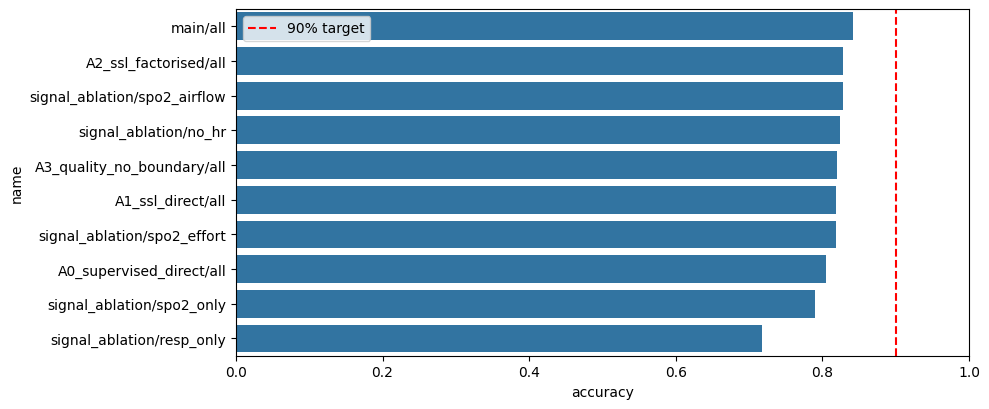

In [12]:
rows = []
for report_path in RESULTS_DIR.glob('*/*/fold_0/test_metrics.json'):
    report = json.loads(report_path.read_text())
    rows.append(dict(experiment=report['experiment_name'], signal_set=report['signal_set'],
                     accuracy=report['test_metrics']['accuracy'],
                     macro_f1=report['test_metrics']['macro_f1'],
                     ahi_mae=report['test_metrics']['ahi_mae']))
ablation_table = pd.DataFrame(rows).sort_values(['accuracy','macro_f1'], ascending=False)
display(ablation_table)
ablation_table.to_csv(RUN_ROOT/'fold0_ablation_summary.csv', index=False)
if len(ablation_table):
    plot_data = ablation_table.copy()
    plot_data['name'] = plot_data.experiment + '/' + plot_data.signal_set
    plt.figure(figsize=(10, max(4, len(plot_data)*0.42)))
    sns.barplot(data=plot_data, y='name', x='accuracy')
    plt.axvline(0.90, color='red', ls='--', label='90% target'); plt.xlim(0, 1); plt.legend()
    plt.tight_layout(); plt.savefig(FIGURE_DIR/'ablation_accuracy.png', dpi=180); plt.show()

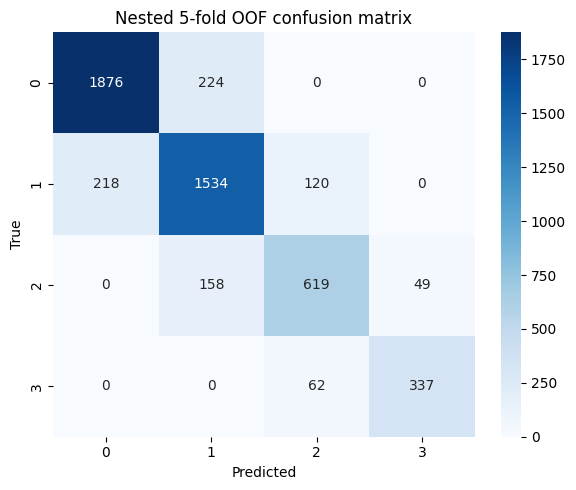

In [13]:
main_oof_path = RESULTS_DIR/'main'/'all'/'aggregate_oof_predictions.parquet'
if main_oof_path.exists():
    main_oof = pd.read_parquet(main_oof_path)
    cm = pd.crosstab(main_oof.target_class, main_oof.predicted_class).reindex(index=range(4), columns=range(4), fill_value=0)
    plt.figure(figsize=(6,5)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Nested 5-fold OOF confusion matrix')
    plt.tight_layout(); plt.savefig(FIGURE_DIR/'main_oof_confusion.png', dpi=180); plt.show()

## 9. Temporal Interpretation of a Single Night and Quality Routing

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


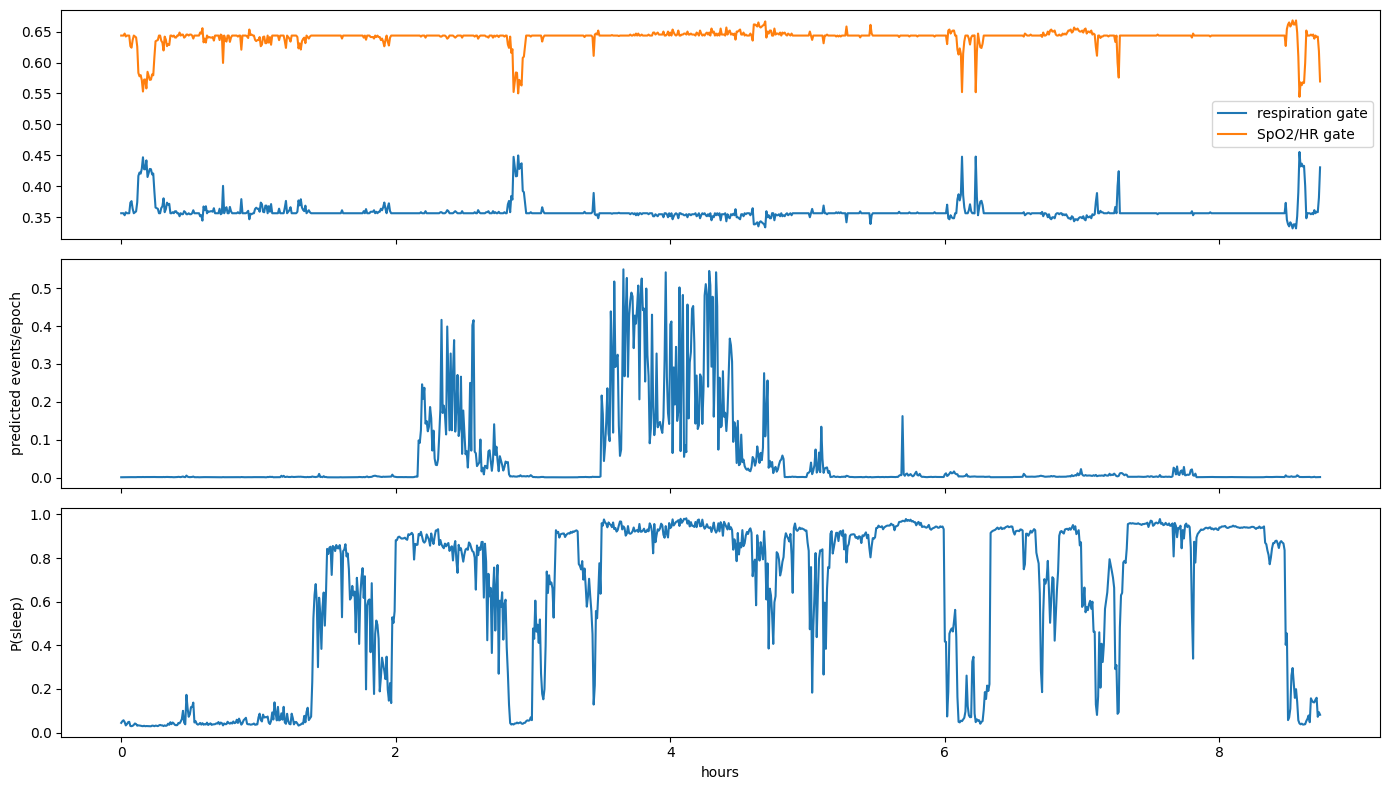

In [14]:
main_checkpoint = RESULTS_DIR/'main'/'all'/'fold_0'/'best_model.pt'
if main_checkpoint.exists() and RUN_MODE != 'smoke':
    from deep_learning.train_supervised import move_batch
    checkpoint = torch.load(main_checkpoint, map_location='cpu', weights_only=False)
    interpret_model = QMHAFNet(ModelConfig(**checkpoint['model_config']))
    interpret_model.load_state_dict(checkpoint['model']); interpret_model.eval()
    fold0_subject = deep_manifest.loc[deep_manifest.fold == 0].iloc[[0]]
    interpret_ds = SHHSRawNightDataset(fold0_subject, Path('deep_learning/data/ahi_a0h3_local_v1/deep_targets.h5'))
    interpret_batch = collate_nights([interpret_ds[0]])
    with torch.no_grad(): out = interpret_model(interpret_batch)
    gate = out['modality_gates'][0].numpy()
    event_rate = out['event_log_rate'][0].exp().numpy()
    sleep_probability = out['sleep_logits'][0].sigmoid().numpy()
    hours = np.arange(len(event_rate))/120
    fig, axes = plt.subplots(3, 1, figsize=(14,8), sharex=True)
    axes[0].plot(hours, gate[:,0], label='respiration gate'); axes[0].plot(hours, gate[:,1], label='SpO2/HR gate'); axes[0].legend()
    axes[1].plot(hours, event_rate); axes[1].set_ylabel('predicted events/epoch')
    axes[2].plot(hours, sleep_probability); axes[2].set_ylabel('P(sleep)'); axes[2].set_xlabel('hours')
    plt.tight_layout(); plt.savefig(FIGURE_DIR/'night_interpretation.png', dpi=180); plt.show()

## 10. Checking the 90% Target and Automatically Packaging Results

In [15]:
status = {'run_mode': RUN_MODE, 'finished_at': time.strftime('%Y-%m-%d %H:%M:%S'),
          'target_version': 'ahi_a0h3_local_v1', 'main_complete': False}
main_metrics_path = RESULTS_DIR/'main'/'all'/'aggregate_metrics.json'
if main_metrics_path.exists():
    main_metrics = json.loads(main_metrics_path.read_text())
    status['main_complete'] = len(main_metrics['folds']) == 5 and main_metrics['subjects'] >= 5000
    status['metrics'] = main_metrics
    status['accuracy_over_90'] = main_metrics['accuracy'] >= 0.90
    print(json.dumps(status, indent=2))
    if not status['accuracy_over_90']:
        print('Scientific warning: Four-class OOF accuracy has not reached 90%; the result must not be reported otherwise.')
else:
    print('Main aggregate metrics are not available.')

(RUN_ROOT/'RUN_COMPLETE.json').write_text(json.dumps(status, indent=2), encoding='utf-8')
result_zip = PROJECT_ROOT/('QMHAF_SMOKE_RESULTS.zip' if RUN_MODE == 'smoke' else 'QMHAF_SERVER_RESULTS.zip')
with zipfile.ZipFile(result_zip, 'w', allowZip64=True) as archive:
    for base in [RESULTS_DIR, RUN_ROOT]:
        if base.exists():
            for path in base.rglob('*'):
                if path.is_file(): archive.write(path, path.resolve().relative_to(PROJECT_ROOT))
print('Result archive:', result_zip, 'size MB:', round(result_zip.stat().st_size/1024**2, 1))

{
  "run_mode": "production",
  "finished_at": "2026-09-21 08:44:43",
  "target_version": "ahi_a0h3_local_v1",
  "main_complete": true,
  "metrics": {
    "subjects": 5197,
    "folds": [
      0,
      1,
      2,
      3,
      4
    ],
    "accuracy": 0.8401000577256109,
    "macro_f1": 0.8310114519222351,
    "balanced_accuracy": 0.8266959949308299,
    "quadratic_kappa": 0.9062665161128243,
    "ahi_mae": 2.1629905136897536,
    "ahi_rmse": 3.7271387832772755,
    "confusion_matrix": [
      [
        1876,
        224,
        0,
        0
      ],
      [
        218,
        1534,
        120,
        0
      ],
      [
        0,
        158,
        619,
        49
      ],
      [
        0,
        0,
        62,
        337
      ]
    ],
    "recall_normal": 0.8933333333333333,
    "recall_mild": 0.8194444444444444,
    "recall_moderate": 0.7493946731234867,
    "recall_severe": 0.8446115288220551,
    "accuracy_95ci": [
      0.8302867038676159,
      0.8499134115836059
